MSDS 7331 Machine Learning I

Instructor: Nedelina Teneva

Koosha Tabesh, Moinak Ghosh, Jacqueline Vu

# Mini Lab: Logistic Regression and SVMs
## Forest Cover Type Dataset: Spruce/Fir vs Lodgepole Pine

The original dataset classifies between 7 different forest cover types. However, since most of the dataset classifies between two forest cover types, spruce/fir (1) and lodgepole pine (2), we decide to just compare the two for this mini lab. From there, we build a logistic regression model and a support vector machine (SVM) to classify the two forest cover types from cartographic variables. After that, we interpret the logistic regression weights and determine which rows the SVM chose as support vectors. Following CRISP-DM, we only cover the parts the rubric asks for: business understanding for this task, data preparation, modeling, and evaluation.

**How we laid out the notebook.** Section 1 explains why we model Spruce/Fir vs Lodgepole Pine as a binary task. Section 2 prepares the data, with most of the code were from our Lab One work, and sets up the 80/20 train/test split and scaling. Section 3 is LDA. Although the rubric does not ask for us to create a LDA, it gives us a quick linear baseline to compare against. Sections 4 and 5 are the two required models: logistic regression and SVM. After that, we follow the rubric's order: section 6 compares the models, section 7 interprets the logistic regression weights, and section 8 looks at the support vectors. Section 9 is our summary.

### Table of Contents

1. [Business Understanding: Why a Binary Task](#business)
2. [Data Preparation](#prep)
    - 2.1 [Loading the data](#load)
    - 2.2 [Preparing the data (carried over from Lab One)](#prepare)
    - 2.3 [Keeping the two largest classes](#filter)
    - 2.4 [Feature selection and train/test split](#split)
    - 2.5 [Scaling](#scaling)
3. [LDA: A Quick Linear Baseline](#lda)
4. [Logistic Regression](#lr)
    - 4.1 [Baseline with repeated 80/20 splits](#lr_base)
    - 4.2 [Tuning C and the penalty](#lr_tune)
    - 4.3 [Final logistic regression on the test set](#lr_final)
5. [Support Vector Machines](#svm)
    - 5.1 [Baseline RBF SVM](#svm_base)
    - 5.2 [Tuning the kernel, C and gamma](#svm_tune)
    - 5.3 [Final RBF SVM on the test set](#svm_final)
    - 5.4 [Linear SVM with SGD on the full training set](#sgd)
6. [Comparing the Models](#compare)
7. [Interpreting the Logistic Regression Weights](#weights)
    - 7.1 [Weights of the final model](#w_full)
    - 7.2 [A smaller feature set with climatic and geologic zones](#w_zone)
    - 7.3 [How few features do we need?](#w_path)
    - 7.4 [The minimal model](#w_min)
    - 7.5 [What the weights tell us](#w_meaning)
8. [Looking at the Support Vectors](#sv)
    - 8.1 [How many support vectors, and from which class](#sv_count)
    - 8.2 [Support vectors vs all training rows](#sv_compare)
9. [Summary of Key Findings](#summary)

**Sources.** The code we have adapted from throughout this mini lab stems from the course notebook (`04. Logits and SVM.ipynb`), our Lab One notebook, and Raschka (2015), *Python Machine Learning*. Find cells that begin with the `# Source:` comment to see which resource we relied on to build our codes.

## <a id="business"></a>1. Business Understanding: Why a Binary Task

Lab One left us with one clear takeaway. As mentioned earlier, most of what makes this dataset hard comes down to two classes: Spruce/Fir and Lodgepole Pine cover about 85% of the 581,012 cells, and they were the pair we could not pull apart. In our parallel coordinates plot, their lines crossed on almost every attribute. In the elevation band heatmap, they shared the 2,900 to 3,200 m range, with neither one clearly on top. The other five cover types split fairly well on elevation and wilderness area alone.

Seeing that, we model that one pair directly: given a cell's cartographic variables, is it Spruce/Fir or Lodgepole Pine? For a land manager, this is the question that matters most. It covers most of the forest. It is also where a cheap GIS based prediction is most likely to go wrong. We code Spruce/Fir as 1 and Lodgepole Pine as 0, so a positive logistic regression weight always means "pushes toward Spruce/Fir."

The tradeoff: these models say nothing about the other five cover types, and our accuracy is not directly comparable to the 7 class results in Blackard and Dean (2000).

## <a id="prep"></a>2. Data Preparation

### <a id="load"></a>2.1 Loading the data

In [1]:
# Source: Lab One notebook (loading cell). Imports added for this lab.
!pip install ucimlrepo -q

import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn import metrics as mt
from sklearn.model_selection import train_test_split, StratifiedShuffleSplit, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import SVC

# fetch from UCI, fall back to a local copy if offline
try:
    from ucimlrepo import fetch_ucirepo
    covertype = fetch_ucirepo(id=31)
    df = pd.concat([covertype.data.features, covertype.data.targets], axis=1)  # combine features + target into one dataframe
except Exception:
    df = pd.read_csv('covtype.csv')

print(df.shape)
df.head()

(581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


### <a id="prepare"></a>2.2 Preparing the data (carried over from Lab One)

These three cells are straight from Lab One: readable labels, the derived features, and the climatic and geologic zones from the ELU codes. The UCI columns keep their names. Lab One found no data errors, so we keep every row.

In [2]:
# Source: Lab One notebook, section 2.2
wilderness_cols = [c for c in df.columns if c.startswith('Wilderness_Area')]
soil_cols = [c for c in df.columns if c.startswith('Soil_Type')]
numeric_cols = ['Elevation','Aspect','Slope','Horizontal_Distance_To_Hydrology',
                'Vertical_Distance_To_Hydrology','Horizontal_Distance_To_Roadways',
                'Hillshade_9am','Hillshade_Noon','Hillshade_3pm',
                'Horizontal_Distance_To_Fire_Points']

print(f"{len(numeric_cols)} numeric attributes, {len(wilderness_cols)} wilderness area "
      f"dummies, {len(soil_cols)} soil type dummies, 1 target (Cover_Type)")

# collapse each one hot block into one column (1 based, like the dataset)
df['wilderness_area'] = df[wilderness_cols].values.argmax(axis=1) + 1
df['soil_type'] = df[soil_cols].values.argmax(axis=1) + 1

cover_type_names = {1: 'Spruce/Fir', 2: 'Lodgepole Pine', 3: 'Ponderosa Pine',
                    4: 'Cottonwood/Willow', 5: 'Aspen', 6: 'Douglas-fir', 7: 'Krummholz'}
df['cover_type_name'] = df['Cover_Type'].map(cover_type_names)

wilderness_names = {1: 'Rawah', 2: 'Neota', 3: 'Comanche Peak', 4: 'Cache la Poudre'}
df['wilderness_area_name'] = df['wilderness_area'].map(wilderness_names)

# same colors as Lab One
cover_type_colors = {
    'Spruce/Fir': '#1f77b4', 'Lodgepole Pine': '#ff7f0e', 'Ponderosa Pine': '#2ca02c',
    'Cottonwood/Willow': '#d62728', 'Aspen': '#9467bd', 'Douglas-fir': '#8c564b',
    'Krummholz': '#e377c2'
}

df[['Elevation','Aspect','wilderness_area_name','soil_type','Cover_Type','cover_type_name']].head()

10 numeric attributes, 4 wilderness area dummies, 40 soil type dummies, 1 target (Cover_Type)


,Elevation,Aspect,wilderness_area_name,soil_type,Cover_Type,cover_type_name
0,2596,51,Rawah,29,5,Aspen
1,2590,56,Rawah,29,5,Aspen
2,2804,139,Rawah,12,2,Lodgepole Pine
3,2785,155,Rawah,30,2,Lodgepole Pine
4,2595,45,Rawah,29,5,Aspen


The counts match Lab One (10 numeric attributes, 4 wilderness areas, and 40 soil types), and each row now has a readable cover type and wilderness area next to its codes.

In [3]:
# Source: Lab One notebook, section 2.8
df['aspect_sin'] = np.sin(np.deg2rad(df['Aspect']))
df['aspect_cos'] = np.cos(np.deg2rad(df['Aspect']))
df['hillshade_range'] = df['Hillshade_9am'] - df['Hillshade_3pm']
df['euclidean_distance_to_hydrology'] = np.sqrt(
    df['Horizontal_Distance_To_Hydrology']**2 + df['Vertical_Distance_To_Hydrology']**2
)

df[['Aspect','aspect_sin','aspect_cos','hillshade_range','euclidean_distance_to_hydrology']].head()

,Aspect,aspect_sin,aspect_cos,hillshade_range,euclidean_distance_to_hydrology
0,51,0.777146,0.629320,73,258.000000
1,56,0.829038,0.559193,69,212.084889
2,139,0.656059,-0.754710,99,275.769832
3,155,0.422618,-0.906308,116,269.235956
4,45,0.707107,0.707107,70,153.003268


The derived features look right. An `Aspect` of 45 degrees becomes 0.71 and 0.71 in `aspect_sin` and `aspect_cos`. The first row's `hillshade_range` is 221 minus 148, or 73. When `Vertical_Distance_To_Hydrology` is 0, the straight line distance to water equals the horizontal one.

In [4]:
# Source: Lab One notebook, section 2.8. ELU codes from covtype.info
# first digit = climatic zone, second digit = geologic zone
elu_codes = [2702,2703,2704,2705,2706,2717,3501,3502,4201,4703,4704,4744,4758,5101,
             5151,6101,6102,6731,7101,7102,7103,7201,7202,7700,7701,7702,7709,7710,
             7745,7746,7755,7756,7757,7790,8703,8707,8708,8771,8772,8776]

climatic_zone_names = {1:'lower montane dry', 2:'lower montane', 3:'montane dry',
                       4:'montane', 5:'montane dry and montane', 6:'montane and subalpine',
                       7:'subalpine', 8:'alpine'}
geologic_zone_names = {1:'alluvium', 2:'glacial', 3:'shale', 4:'sandstone',
                       5:'mixed sedimentary', 6:'unspecified', 7:'igneous and metamorphic', 8:'volcanic'}

soil_to_climatic = {i+1: climatic_zone_names[int(str(code)[0])] for i, code in enumerate(elu_codes)}
soil_to_geologic = {i+1: geologic_zone_names[int(str(code)[1])] for i, code in enumerate(elu_codes)}

df['climatic_zone'] = df['soil_type'].map(soil_to_climatic)
df['geologic_zone'] = df['soil_type'].map(soil_to_geologic)

print(df.shape)
df[['soil_type','climatic_zone','geologic_zone']].head()

(581012, 65)


,soil_type,climatic_zone,geologic_zone
0,29,subalpine,igneous and metamorphic
1,29,subalpine,igneous and metamorphic
2,12,montane,igneous and metamorphic
3,30,subalpine,igneous and metamorphic
4,29,subalpine,igneous and metamorphic


Every soil type now maps to a climatic and a geologic zone. The first rows are mostly subalpine soils on igneous and metamorphic rock. The dataframe has 65 columns: the 55 originals plus the 10 we added.

### <a id="filter"></a>2.3 Keeping the two largest classes

We keep classes 1 and 2, build a 0/1 target, and check which one hot columns end up empty once the other five classes are gone.

In [5]:
# keep Spruce/Fir (1) and Lodgepole Pine (2)
df_bin = df[df['Cover_Type'].isin([1, 2])].copy().reset_index(drop=True)

# target: 1 = Spruce/Fir, 0 = Lodgepole Pine
df_bin['is_spruce_fir'] = (df_bin['Cover_Type'] == 1).astype(int)

print(df_bin.shape)

class_balance = pd.DataFrame({
    'Count': df_bin['cover_type_name'].value_counts(),
    'Percentage': (df_bin['cover_type_name'].value_counts(normalize=True) * 100).round(2)
})
display(class_balance)

# one hot columns left with no rows after filtering
empty_cols = [c for c in wilderness_cols + soil_cols if df_bin[c].sum() == 0]
print(f"\nOne hot columns with no rows left after filtering ({len(empty_cols)}):")
print(empty_cols)

(495141, 66)


,Count,Percentage
cover_type_name,,
Lodgepole Pine,283301,57.22
Spruce/Fir,211840,42.78



One hot columns with no rows left after filtering (5):
['Soil_Type1', 'Soil_Type5', 'Soil_Type14', 'Soil_Type15', 'Soil_Type37']


We are left with 495,141 rows: 57.22% Lodgepole Pine and 42.78% Spruce/Fir. Always guessing Lodgepole Pine would be right 57.22% of the time, so that is the baseline every model needs to beat. Instead of classifying Spruce/Fir as 1 and Lodgepole Pine as 2, we keep Spruce/Fir as 1 and change Lodgepole Pine to 0 to make classification easier when utilizing our classification prediction models.

Aside from changing how we classify the two forest cover types, we check which one hot columns are empty after reducing the dataset size. Five soil columns came back empty (`Soil_Type1`, `Soil_Type5`, `Soil_Type14`, `Soil_Type15`, and `Soil_Type37`). Four are lower montane or montane dry soils, where Ponderosa Pine, Douglas-fir and Cottonwood/Willow grow. The fifth is alpine, which is Krummholz ground. We see the same elevation zoning that we saw in Lab One and since they carry no information here, we drop them.

### <a id="split"></a>2.4 Feature selection and train/test split

We end up with 50 features. The numeric measures of `Aspect` are swapped for `aspect_sin` and `aspect_cos`, since Lab One showed `Aspect` is circular. Then, we keep the 4 wilderness columns and the 35 soil columns, as they still have information in each row. We leave out `hillshade_range` because it is exactly `Hillshade_9am` minus `Hillshade_3pm`, and with all three in, the logistic regression weights would be arbitrary. We also leave out `euclidean_distance_to_hydrology` since it is built from two columns that are already in. In regards to the zones, we will go into more details in section 7.

The train/test split is 80/20, stratified so both sides keep the 57/43 ratio, with `random_state = 42`. Each model sees the test set once, for its final score. All tuning uses cross validation inside the training set.

In [6]:
# numeric measures with Aspect swapped for sin/cos, plus the non empty one hot columns
numeric_features = [c for c in numeric_cols if c != 'Aspect'] + ['aspect_sin', 'aspect_cos']
onehot_features = [c for c in wilderness_cols + soil_cols if c not in empty_cols]
feature_cols = numeric_features + onehot_features

X = df_bin[feature_cols]
y = df_bin['is_spruce_fir']

# 80/20 split, stratified on the target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Features: {len(feature_cols)} ({len(numeric_features)} numeric, {len(onehot_features)} one hot)")
print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print("\nSpruce/Fir share in train: {:.2%}".format(y_train.mean()))
print("Spruce/Fir share in test:  {:.2%}".format(y_test.mean()))

Features: 50 (11 numeric, 39 one hot)
Train: (396112, 50), Test: (99029, 50)

Spruce/Fir share in train: 42.78%
Spruce/Fir share in test:  42.78%


There are 396,112 rows for the training dataset and 99,029 for the test dataset, with 42.78% of both datasets being classified as Spruce/Fir, so the stratification is held.

### <a id="scaling"></a>2.5 Scaling

We standardize everything to mean of 0 and standard deviation of 1. We need it for all three models: to compare logistic regression weights, because the RBF kernel works on distances, and because stochastic gradient descent (SGD) handles unscaled data badly. Like the course notebook, the scaler is fit on the training set only. We scale the one hot columns too, as the course notebook does with its dummies, so every weight is per standard deviation and all of them can be ranked together.

In [7]:
# Source: course notebook, cell 18 (scaler fit on the training set only)
scl_obj = StandardScaler()
scl_obj.fit(X_train)

X_train_scaled = pd.DataFrame(scl_obj.transform(X_train), columns=feature_cols, index=X_train.index)
X_test_scaled = pd.DataFrame(scl_obj.transform(X_test), columns=feature_cols, index=X_test.index)

# check: mean ~0, std ~1
X_train_scaled[numeric_features].describe().loc[['mean', 'std']].round(3)

,Elevation,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,aspect_sin,aspect_cos
mean,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Every numeric column now has mean of 0 and standard deviation of 1 on the training set. The test set goes through the same scaler, so its values land close to that but not exactly.

## <a id="lda"></a>3. LDA: A Quick Linear Baseline

This is not part of the rubric, but we ran a LDA first to get a linear baseline before the two required models. Blackard and Dean also used LDA on this data, so it ties back to the original study. With two classes, there is only one discriminant axis: LD1.

LDA training time: 2.45 s
LDA test accuracy: 0.7777
Confusion matrix:
 [[46511 10150]
 [11865 30503]]


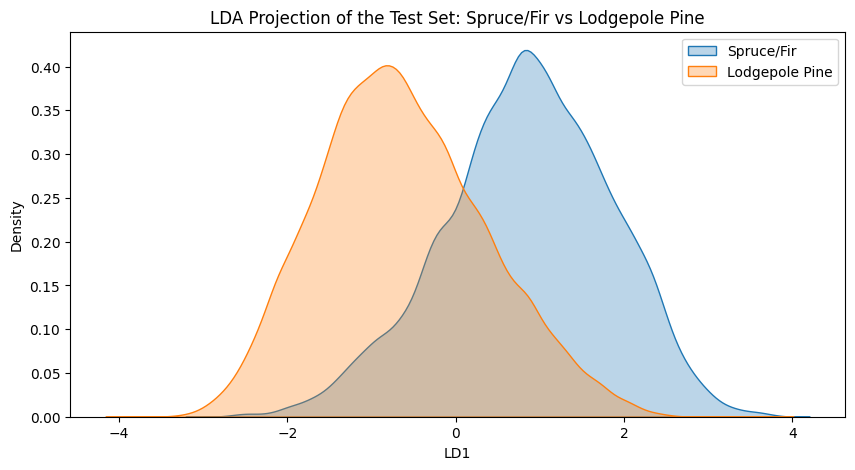

In [8]:
# LDA baseline. 2 classes, so only 1 discriminant axis
lda = LDA(solver='svd')
start = time.time()
lda.fit(X_train_scaled, y_train)
lda_time = time.time() - start

y_hat_lda = lda.predict(X_test_scaled)
print(f"LDA training time: {lda_time:.2f} s")
print("LDA test accuracy: {:.4f}".format(mt.accuracy_score(y_test, y_hat_lda)))
print("Confusion matrix:\n", mt.confusion_matrix(y_test, y_hat_lda))

# test set along LD1, by class
ld1_test = lda.transform(X_test_scaled)[:, 0]
plt.figure(figsize=(10, 5))
for label, name in [(1, 'Spruce/Fir'), (0, 'Lodgepole Pine')]:
    sns.kdeplot(ld1_test[y_test.values == label], label=name,
                color=cover_type_colors[name], fill=True, alpha=0.3)
plt.xlabel('LD1')
plt.title('LDA Projection of the Test Set: Spruce/Fir vs Lodgepole Pine')
plt.legend()
plt.show()

LDA predicts forest cover types accurately 77.77% of the time on the test set. It misses 11,865 Spruce/Fir cells and 10,150 Lodgepole Pine cells, so Spruce/Fir is already the harder class to predict. The two curves overlap a lot along LD1.

In Lab One, our LDA scatterplot had two axes because there were 7 classes. Here, there is no LD2, so we plot LD1 against `Elevation` instead, on a 20,000 row sample of the test set.

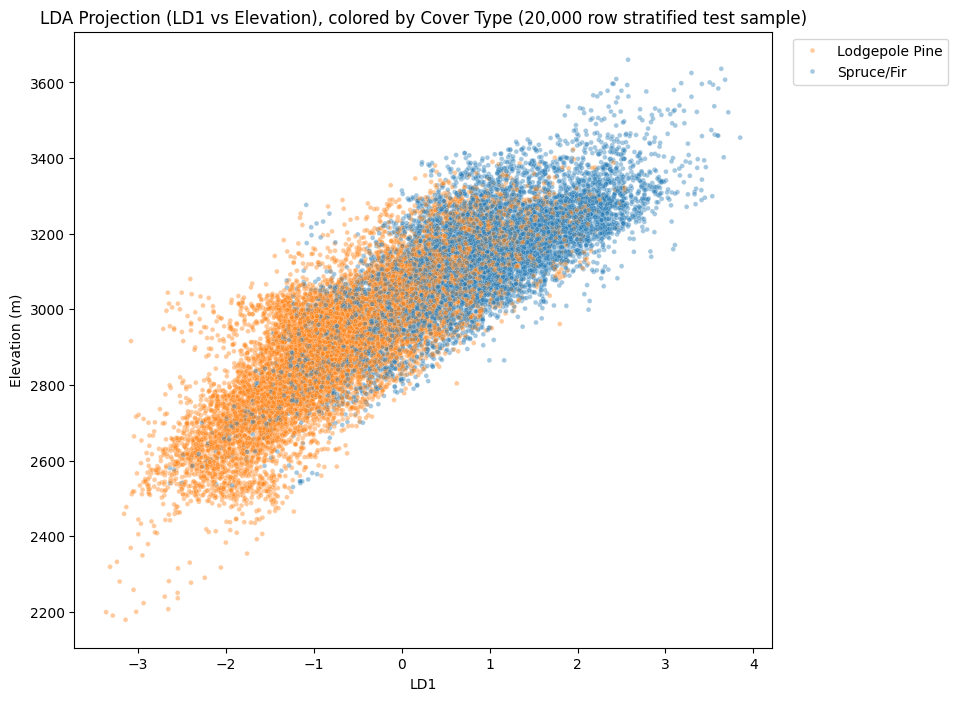

In [9]:
# Source: Lab One notebook (LDA scatter). No LD2 with 2 classes, so Elevation is the y axis
X_test_sample, _, y_test_sample, _ = train_test_split(
    X_test_scaled, y_test, train_size=20000, stratify=y_test, random_state=42)

X_lda = lda.transform(X_test_sample)

df_lda = pd.DataFrame(X_lda, columns=['LD1'])
df_lda['Elevation'] = X_test.loc[X_test_sample.index, 'Elevation'].values
df_lda['cover_type'] = np.where(y_test_sample.values == 1, 'Spruce/Fir', 'Lodgepole Pine')

plt.figure(figsize=(9, 8))
ax = sns.scatterplot(data=df_lda, x='LD1', y='Elevation', hue='cover_type', alpha=0.4, s=12, palette=cover_type_colors)
plt.title('LDA Projection (LD1 vs Elevation), colored by Cover Type (20,000 row stratified test sample)')
plt.ylabel('Elevation (m)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

The points form a tight diagonal band, so LD1 is mostly elevation. Both colors mix in the middle of that band. A straight line cannot split that part, and we kept running into it in every linear model below.

## <a id="lr"></a>4. Logistic Regression

To construct our logistic regression model, we build a for loop that repeats the 80/20 train/test split to check for stability, producing the accuracy score and confusion matrix on the validation fold for each iteration. Then we run a grid search over the C and the penalty values, and score the final model once on the test set. The splits are running on the scaled training set, so each validation fold was part of the scaler's fit.

### <a id="lr_base"></a>4.1 Baseline with repeated 80/20 splits

In [10]:
# Source: course notebook, cells 9 and 11. Changed: stratified splits, fixed seed, training set only
cv_object = StratifiedShuffleSplit(n_splits=3, test_size=0.2, random_state=42)

lr_clf = LogisticRegression(penalty='l2', C=1.0, solver='liblinear')

for iter_num, (train_idx, val_idx) in enumerate(cv_object.split(X_train_scaled, y_train)):
    lr_clf.fit(X_train_scaled.iloc[train_idx], y_train.iloc[train_idx])
    y_hat = lr_clf.predict(X_train_scaled.iloc[val_idx])

    print("====Iteration", iter_num, "====")
    print("accuracy: {:.4f}".format(mt.accuracy_score(y_train.iloc[val_idx], y_hat)))
    print("Confusion matrix:\n", mt.confusion_matrix(y_train.iloc[val_idx], y_hat))

====Iteration 0 ====
accuracy: 0.7768
Confusion matrix:
 [[37174  8154]
 [ 9525 24370]]


====Iteration 1 ====
accuracy: 0.7708
Confusion matrix:
 [[36854  8474]
 [ 9683 24212]]


====Iteration 2 ====
accuracy: 0.7741
Confusion matrix:
 [[37081  8247]
 [ 9647 24248]]


The three splits land between accuracy scores of 77.1% and 77.7%. With about 79,000 rows in each validation fold, the split itself does not move the result much. The confusion matrices agree too. In every split, 9,500 to 9,700 Spruce/Fir cells get called Lodgepole Pine, compared with 8,150 to 8,500 errors the other way.

### <a id="lr_tune"></a>4.2 Tuning C and the penalty

The course notebook uses a slider for C. We used a fixed grid so the results stay in the report, and for the penalty value, we tried both L2 and L1. `GridSearchCV` runs all 12 settings on the same three splits, in parallel with `n_jobs = -1` (which uses all available CPU cores), and reports the average time per fit.

,param_penalty,param_C,mean_test_score,std_test_score,mean_fit_time
0,l2,0.001,0.7739,0.0025,6.9606
1,l1,0.001,0.7748,0.0021,2.6235
2,l2,0.010,0.7739,0.0025,11.1376
3,l1,0.010,0.7740,0.0025,31.9232
4,l2,0.050,0.7739,0.0025,14.5623
5,l1,0.050,0.7739,0.0025,26.2240
6,l2,0.100,0.7740,0.0025,14.7767
7,l1,0.100,0.7739,0.0025,41.0183
8,l2,1.000,0.7739,0.0025,15.2532
9,l1,1.000,0.7739,0.0025,72.7808


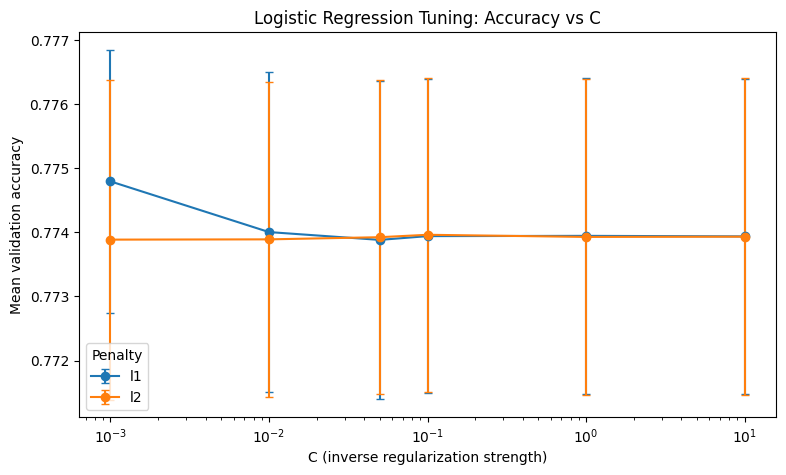

Best: {'C': 0.001, 'penalty': 'l1'} -> 0.7748


In [11]:
# Source: course notebook, cell 14 (C slider), done here as a grid search
# n_jobs=-1 uses all available CPU cores
lr_search = GridSearchCV(LogisticRegression(solver='liblinear'),
                         {'penalty': ['l2', 'l1'], 'C': [0.001, 0.01, 0.05, 0.1, 1, 10]},
                         cv=cv_object, n_jobs=-1, refit=False)
lr_search.fit(X_train_scaled, y_train)

lr_tuning_df = pd.DataFrame(lr_search.cv_results_)
display(lr_tuning_df[['param_penalty', 'param_C', 'mean_test_score', 'std_test_score', 'mean_fit_time']].round(4))

plt.figure(figsize=(9, 5))
for penalty, grp in lr_tuning_df.groupby('param_penalty'):
    plt.errorbar(grp['param_C'].astype(float), grp['mean_test_score'], yerr=grp['std_test_score'],
                 marker='o', capsize=3, label=penalty)
plt.xscale('log')
plt.xlabel('C (inverse regularization strength)')
plt.ylabel('Mean validation accuracy')
plt.title('Logistic Regression Tuning: Accuracy vs C')
plt.legend(title='Penalty')
plt.show()

best_lr = lr_search.best_params_
print("Best:", best_lr, "-> {:.4f}".format(lr_search.best_score_))

Tuning the logistic regression model did not make any significant changes. All 12 settings land between 77.39% and 77.48%, and that spread is smaller than the standard deviation across splits. The plot exaggerates the gaps because its y axis covers only half a point. With about 317,000 rows per fit and only 50 features, the weights are already pinned down and regularization has little to fix. Therefore, the remaining error is not a tuning problem. It looks like a limit of the linear model, which is what we will test with the SVM.

We pick L1 at C = 0.001. Its accuracy edge is within noise. We choose it because it is the strongest penalty we tried, the fastest (2.62 seconds per fit), and L1 zeroes out weak features, which makes the weights easier to read. L1 also got slower as C grew, up to 72.78 seconds per fit, since a weaker penalty leaves more weights to fit.

### <a id="lr_final"></a>4.3 Final logistic regression on the test set

We refit L1 with C = 0.001 on the whole training set and score it once on the test set.

In [12]:
# final model with the best settings, scored once on the test set
lr_clf = LogisticRegression(penalty=best_lr['penalty'], C=best_lr['C'], solver='liblinear')

start = time.time()
lr_clf.fit(X_train_scaled, y_train)
lr_time = time.time() - start

y_hat_lr = lr_clf.predict(X_test_scaled)
print(f"Logistic Regression training time: {lr_time:.2f} s")
print("Logistic Regression test accuracy: {:.4f}".format(mt.accuracy_score(y_test, y_hat_lr)))
print("Baseline (always Lodgepole Pine): {:.4f}".format(1 - y_test.mean()))
print("Confusion matrix:\n", mt.confusion_matrix(y_test, y_hat_lr))
print(mt.classification_report(y_test, y_hat_lr, target_names=['Lodgepole Pine', 'Spruce/Fir']))

# features L1 kept
print((lr_clf.coef_[0] != 0).sum(), "of", len(feature_cols), "features kept")

Logistic Regression training time: 3.59 s
Logistic Regression test accuracy: 0.7788
Baseline (always Lodgepole Pine): 0.5722
Confusion matrix:
 [[46519 10142]
 [11768 30600]]
                precision    recall  f1-score   support

Lodgepole Pine       0.80      0.82      0.81     56661
    Spruce/Fir       0.75      0.72      0.74     42368

      accuracy                           0.78     99029
     macro avg       0.77      0.77      0.77     99029
  weighted avg       0.78      0.78      0.78     99029

32 of 50 features kept


Our final accuracy score on the test set is 77.88%, which is greater than the accuracy score of 77.48% that we got from cross validation, thus, there is no sign of overfitting. That is about 20.7 percentage points over the baseline of 57.22%.

The errors are lopsided as 11,768 Spruce/Fir cells got called Lodgepole Pine, and 10,142 Lodgepole Pine cells were classified as Spruce/Fir. The recall is 0.82 for Lodgepole Pine and only 0.72 for Spruce/Fir, so there is a mild pull toward the bigger class. The macro F1 average is 0.77, which is close to the accuracy score of 77.88%, so neither class is being ignored. This is the check we said in Lab One we would need beyond plain accuracy.

The penalty value of L1 keeps 32 of the 50 features with no accuracy cost. Training on all 396,112 rows took 3.59 seconds. We will come back to the weights in section 7.

## <a id="svm"></a>5. Support Vector Machines

A kernel SVM on all 396,112 training rows is not practical since its training time grows much faster than the row count. Seeing that, we train the RBF SVM on a 20,000 row stratified subsample of the training set, the same sample size we used for PCA and LDA in Lab One. It is still scored on the full test set, and tuning it relies on the same three splits we used for the logistic regression model. To cover the full training set as well, section 5.4 trains a linear SVM with SGD on all rows, in which the instructions allow for large data.

### <a id="svm_base"></a>5.1 Baseline RBF SVM

In [13]:
# Source: course notebook, cell 28. Changed: 20,000 row stratified subsample, scored on the full test set
X_svm_train, _, y_svm_train, _ = train_test_split(
    X_train_scaled, y_train, train_size=20000, stratify=y_train, random_state=42)

svm_clf = SVC(kernel='rbf', C=0.5, gamma='auto', cache_size=2000)

start = time.time()
svm_clf.fit(X_svm_train, y_svm_train)
print(f"Training time: {time.time() - start:.2f} s")

start = time.time()
y_hat_svm = svm_clf.predict(X_test_scaled)
print(f"Prediction time on test set: {time.time() - start:.2f} s")

print("Test accuracy: {:.4f}".format(mt.accuracy_score(y_test, y_hat_svm)))
print("Confusion matrix:\n", mt.confusion_matrix(y_test, y_hat_svm))

Training time: 11.74 s


Prediction time on test set: 61.28 s
Test accuracy: 0.8037
Confusion matrix:
 [[48099  8562]
 [10873 31495]]


With the course notebook's settings (C = 0.5, gamma = 'auto'), the SVM already has an accuracy score of 80.37% from just 20,000 rows. Logistic regression only got an accuracy score of 77.88% from all 396,112 rows, and no amount of tuning increased the accuracy score past 77.5%. Therefore, the boundary between the two species is not a straight line. That aligns to what we saw in Lab One, where the elevation handoff between them shifted from one wilderness area to the next.

The catch is speed as training the SVM in the training set took 11.74 seconds, but predicting the 99,029 rows in the test set took 61.28 seconds as each new row gets compared against every support vector.

### <a id="svm_tune"></a>5.2 Tuning the kernel, C and gamma

Next, we tried a linear kernel and an RBF kernel with three values, each with a combination of a C value, from 0.5 to 10, and a gamma value, from very smooth (gamma = 'auto') to much tighter (gamma = 0.5). `GridSearchCV` runs all 11 settings on the same three splits and reports the average time per fit.

In [14]:
# Source: Raschka (2015), pp. 186 to 187 (grid search over linear and RBF SVMs)
param_grid = [{'kernel': ['linear'], 'C': [0.5, 1]},
              {'kernel': ['rbf'], 'C': [0.5, 1, 10], 'gamma': ['auto', 0.1, 0.5]}]

# n_jobs=-1 uses all available CPU cores
svm_search = GridSearchCV(SVC(cache_size=2000), param_grid, cv=cv_object, n_jobs=-1, refit=False)
svm_search.fit(X_svm_train, y_svm_train)

print("Best:", svm_search.best_params_, "-> {:.4f}".format(svm_search.best_score_))

svm_tuning_df = pd.DataFrame(svm_search.cv_results_)
svm_tuning_df[['params', 'mean_test_score', 'std_test_score', 'mean_fit_time']].sort_values(
    'mean_test_score', ascending=False).round(4)

Best: {'C': 1, 'gamma': 0.5, 'kernel': 'rbf'} -> 0.8582


,params,mean_test_score,std_test_score,mean_fit_time
7,"{'C': 1, 'gamma': 0.5, 'kernel': 'rbf'}",0.8582,0.0071,10.5017
10,"{'C': 10, 'gamma': 0.5, 'kernel': 'rbf'}",0.8569,0.0052,11.9448
9,"{'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}",0.8532,0.0059,8.4120
4,"{'C': 0.5, 'gamma': 0.5, 'kernel': 'rbf'}",0.8463,0.0062,10.6680
6,"{'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}",0.8346,0.0026,7.6383
8,"{'C': 10, 'gamma': 'auto', 'kernel': 'rbf'}",0.8273,0.0038,8.0083
3,"{'C': 0.5, 'gamma': 0.1, 'kernel': 'rbf'}",0.8260,0.0034,7.8190
5,"{'C': 1, 'gamma': 'auto', 'kernel': 'rbf'}",0.8090,0.0050,7.0943
2,"{'C': 0.5, 'gamma': 'auto', 'kernel': 'rbf'}",0.8042,0.0042,6.9535
0,"{'C': 0.5, 'kernel': 'linear'}",0.7822,0.0046,11.4241


Tuning matters a lot here as the linear kernel stops at an accuracy score of 78.2%, right where the accuracy score of our logistic regression was, whereas the RBF kernel has an accuracy score that is slightly above 85%. Therefore, this increase in the accuracy score stems from the curved boundary, not from switching to an SVM.

Within RBF, rather than the C value, gamma is what causes the accuracy score to change. At every C value, the accuracy score increases as gamma goes from 'auto' (1/50 = 0.02) to 0.1 to 0.5. At gamma = 0.5, C = 1 and C = 10 are within noise (accuracy score of 85.82% vs 85.69%), so we kept C = 1, the smoother of the two. However, there is one limitation we encounter: 0.5 was the largest value of our gamma grid, and with that, the accuracy score was still increasing, so we believe that a slightly larger gamma value might improve our accuracy score.

### <a id="svm_final"></a>5.3 Final RBF SVM on the test set

We refit the SVM with C = 1 and gamma = 0.5 on the same 20,000 rows and score it once on the full test set.

In [15]:
# final SVM with the best settings, scored once on the test set
svm_clf = SVC(**svm_search.best_params_, cache_size=2000)

start = time.time()
svm_clf.fit(X_svm_train, y_svm_train)
print(f"Training time: {time.time() - start:.2f} s")

start = time.time()
y_hat_svm = svm_clf.predict(X_test_scaled)
print(f"Prediction time on test set: {time.time() - start:.2f} s")

print("SVM test accuracy: {:.4f}".format(mt.accuracy_score(y_test, y_hat_svm)))
print("Logistic Regression test accuracy: {:.4f}".format(mt.accuracy_score(y_test, y_hat_lr)))
print("Confusion matrix:\n", mt.confusion_matrix(y_test, y_hat_svm))
print(mt.classification_report(y_test, y_hat_svm, target_names=['Lodgepole Pine', 'Spruce/Fir']))
print("Support vectors:", len(svm_clf.support_), "of", len(X_svm_train), "training rows")

Training time: 16.85 s


Prediction time on test set: 72.89 s
SVM test accuracy: 0.8663
Logistic Regression test accuracy: 0.7788
Confusion matrix:
 [[51411  5250]
 [ 7989 34379]]
                precision    recall  f1-score   support

Lodgepole Pine       0.87      0.91      0.89     56661
    Spruce/Fir       0.87      0.81      0.84     42368

      accuracy                           0.87     99029
     macro avg       0.87      0.86      0.86     99029
  weighted avg       0.87      0.87      0.87     99029

Support vectors: 12252 of 20000 training rows


We got an accuracy score of 86.63% on the test set, which is slightly above the accuracy score of 85.82% from the cross validation. Therefore, the SVM is not overfitting its 20,000 rows. That is 8.75 percentage points above the accuracy score we got from our logistic regression model, with about 40% fewer errors (13,239 vs 21,910). Additionally, recall for both classes and the macro F1 average increased after using the SVM instead of the logistic regression model. Lodgepole Pine's recall increased from 0.82 to 0.91, and Spruce/Fir's recall increased from 0.72 to 0.81. The macro F1 average increased from 0.77 to 0.86.

Training the SVM took 16.85 seconds, and prediction took 72.89 seconds. 12,252 of the 20,000 rows, about 61%, ended up as support vectors, and every prediction is checked against all of them. Section 8 looks at who those rows are.

### <a id="sgd"></a>5.4 Linear SVM with SGD on the full training set

The instructions allow a linear kernel with SGD for large data, so this SVM trains on all 396,112 rows instead of a subsample. We tune alpha, which is the regularization strength, on the same three splits, before comparing its weights with logistic regression's.

In [16]:
# Source: course notebook, cell 39. Changed: alpha tuned with a grid search, fixed seed, max_iter/tol instead of n_iter
sgd = SGDClassifier(loss='hinge', penalty='l2', max_iter=1000, tol=1e-3, random_state=42)

# n_jobs=-1 uses all available CPU cores
sgd_search = GridSearchCV(sgd, {'alpha': [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]}, cv=cv_object, n_jobs=-1, refit=False)
sgd_search.fit(X_train_scaled, y_train)

sgd_tuning_df = pd.DataFrame(sgd_search.cv_results_)
display(sgd_tuning_df[['param_alpha', 'mean_test_score', 'std_test_score', 'mean_fit_time']].round(
    {'mean_test_score': 4, 'std_test_score': 4, 'mean_fit_time': 2}))
print("Best:", sgd_search.best_params_)

# final linear SVM on all training rows
svm_sgd = sgd.set_params(**sgd_search.best_params_)

start = time.time()
svm_sgd.fit(X_train_scaled, y_train)
print(f"\nTraining time on {len(X_train_scaled)} rows: {time.time() - start:.2f} s")

y_hat_sgd = svm_sgd.predict(X_test_scaled)
print("Linear SVM (SGD) test accuracy: {:.4f}".format(mt.accuracy_score(y_test, y_hat_sgd)))
print("Logistic Regression test accuracy: {:.4f}".format(mt.accuracy_score(y_test, y_hat_lr)))
print("RBF SVM test accuracy:             {:.4f}".format(mt.accuracy_score(y_test, y_hat_svm)))
print("Confusion matrix:\n", mt.confusion_matrix(y_test, y_hat_sgd))
print(mt.classification_report(y_test, y_hat_sgd, target_names=['Lodgepole Pine', 'Spruce/Fir']))

# Source: course notebook, cell 30 (linear SVM weights). Compared with logistic regression
print("Correlation between the two weight vectors: {:.3f}".format(np.corrcoef(lr_clf.coef_[0], svm_sgd.coef_[0])[0, 1]))
compare_w = pd.DataFrame({'logistic_regression': lr_clf.coef_[0], 'linear_svm': svm_sgd.coef_[0]}, index=feature_cols)
compare_w.reindex(compare_w['linear_svm'].abs().sort_values(ascending=False).index).head(10).round(3)

,param_alpha,mean_test_score,std_test_score,mean_fit_time
0,0.000001,0.7492,0.0083,15.36
1,0.000010,0.7674,0.0064,5.70
2,0.000100,0.7729,0.0035,2.15
3,0.001000,0.7748,0.0037,1.21
4,0.010000,0.7752,0.0025,0.99


Best: {'alpha': 0.01}



Training time on 396112 rows: 1.27 s
Linear SVM (SGD) test accuracy: 0.7798
Logistic Regression test accuracy: 0.7788
RBF SVM test accuracy:             0.8663
Confusion matrix:
 [[46534 10127]
 [11676 30692]]
                precision    recall  f1-score   support

Lodgepole Pine       0.80      0.82      0.81     56661
    Spruce/Fir       0.75      0.72      0.74     42368

      accuracy                           0.78     99029
     macro avg       0.78      0.77      0.77     99029
  weighted avg       0.78      0.78      0.78     99029

Correlation between the two weight vectors: 0.987


,logistic_regression,linear_svm
Elevation,1.614,1.327
Horizontal_Distance_To_Hydrology,-0.392,-0.282
Soil_Type32,-0.123,-0.184
Hillshade_Noon,-0.200,-0.184
Horizontal_Distance_To_Roadways,-0.110,-0.173
Soil_Type22,0.212,0.165
Soil_Type23,0.194,0.149
Wilderness_Area2,-0.171,-0.096
aspect_cos,0.215,0.087
Soil_Type20,0.098,0.083


The linear SVM has an accuracy score of 77.98% with a runtime of 1.27 seconds on all training rows, the fastest full data fit we have run. The accuracy score has increased with alpha. The smallest alpha was the worst on both counts, an accuracy score of 74.92% with a runtime of 15.36 seconds per fit, because SGD is barely regularized there and bounces around. The best alpha (0.01) sits at the edge of the grid, but the last two values differ by only 0.04 points, so going further would not change anything.

Its confusion matrix is almost identical to logistic regression's. The two weight vectors correlate at 0.987, with the same features on top.

## <a id="compare"></a>6. Comparing the Models

| Model | Training rows | Test accuracy | Macro F1 | Training time | Prediction time (99,029 rows) |
|---|---|---|---|---|---|
| Baseline: always Lodgepole Pine | | 57.22% | | | |
| LDA | 396,112 | 77.77% | | 2.45 s | near instant |
| Logistic regression (L1, C = 0.001) | 396,112 | 77.88% | 0.77 | 3.59 s | near instant |
| Linear SVM with SGD (alpha = 0.01) | 396,112 | 77.98% | 0.77 | 1.27 s | near instant |
| RBF SVM (C = 1, gamma = 0.5) | 20,000 | 86.63% | 0.86 | 16.85 s | 72.89 s |

**Prediction accuracy.** The RBF SVM wins clearly with an accuracy score of 86.63%. Logistic regression (accuracy score of 77.88%) and the linear SVM (accuracy score of 77.98%) are tied, and their confusion matrices differ by fewer than 100 cells in any position. The linear kernel SVM from our grid has a similar accuracy score of 78.2%, as well as LDA with an accuracy score of 77.77%. Seeing that, the increase in accuracy score is not about using an SVM instead of logistic regression. Rather, it is about the curved boundary. With a straight boundary, every method we tried stops around 78%. Raschka makes the same point that linear logistic regression and linear SVMs often give very similar results. Seeing that, our weights back it up (correlation 0.987).

Lab One already suggested why curvature helps. The elevation where Spruce/Fir takes over from Lodgepole Pine is not fixed. It shifts between wilderness areas and with slope direction and distance to water. A linear model has to draw one flat cut through all of that. The RBF kernel can bend the boundary locally.

**Training time and efficiency.** Here, the order flips. The linear SVM trained on all 396,112 rows has a runtime of 1.27 seconds, while the logistic regression has a runtime of 3.59 seconds. Both predict the test set almost instantly since each prediction is one weighted sum. The RBF SVM has a runtime of 16.85 seconds on only 20,000 rows and a runtime of 72.89 seconds to predict because every prediction is checked against all 12,252 support vectors. Its training time grows much faster than the row count, which is why we subsampled in the first place. Tuning the models shows the same gap. Each logistic regression fit took 3 to 73 seconds of runtime on about 317,000 rows. Each RBF fit took 7 to 12 seconds of runtime on only 16,000 rows. These times depend on the machine, so they will differ on another computer, but the order between the models does not change.

**Advantages of each model.** Logistic regression gives weights that turn straight into odds, trains in seconds on all the data, and with L1, it shrinks to six features for a 0.6 point loss (section 7). The linear SVM with SGD is the fastest and scales to any size. It hits the same accuracy ceiling, though, and since hinge loss gives no probabilities, its weights are harder to read. The RBF SVM is the most accurate by far, with 5% of the data. The price for having the highest accuracy rate is slow training, slow prediction, and no weights to interpret.

For the most accurate cover type map, we would pick the RBF SVM. However, to understand which terrain factors separate the two species, or to predict over a whole national forest quickly, logistic regression is the better fit.

## <a id="weights"></a>7. Interpreting the Logistic Regression Weights

### <a id="w_full"></a>7.1 Weights of the final model

Every feature is standardized, so each weight is the change in log odds of Spruce/Fir per one standard deviation, holding the others fixed. Positive pushes toward Spruce/Fir, whereas negative pushes toward Lodgepole Pine. Like the course notebook, we also refit on each of the three splits and use the spread as error bars.

Features dropped by L1 (18):
['Slope', 'Hillshade_3pm', 'aspect_sin', 'Wilderness_Area1', 'Wilderness_Area3', 'Wilderness_Area4', 'Soil_Type2', 'Soil_Type3', 'Soil_Type4', 'Soil_Type6', 'Soil_Type8', 'Soil_Type10', 'Soil_Type11', 'Soil_Type18', 'Soil_Type27', 'Soil_Type28', 'Soil_Type31', 'Soil_Type33']


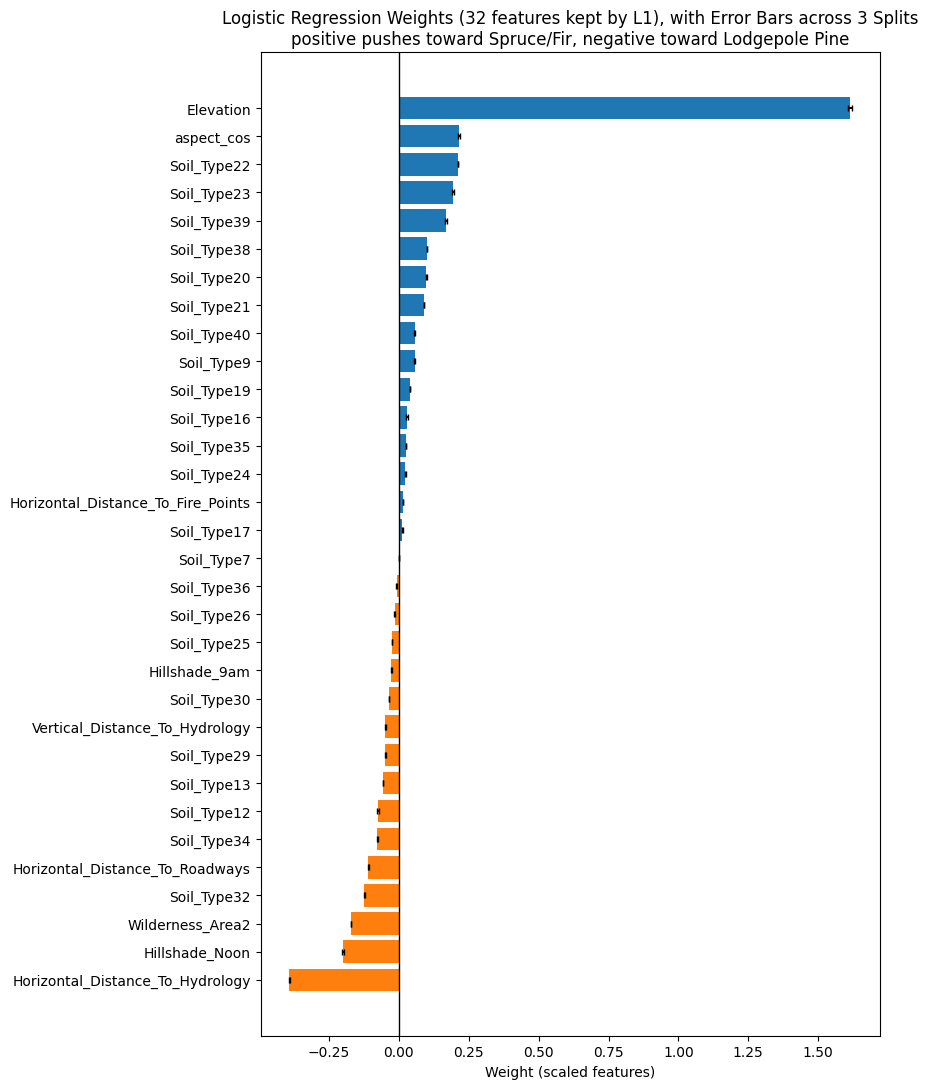

,weight,split_std
Elevation,1.614104,0.006541
Horizontal_Distance_To_Hydrology,-0.391792,0.001759
aspect_cos,0.214897,0.003289
Soil_Type22,0.212098,0.001149
Hillshade_Noon,-0.200214,0.004056
Soil_Type23,0.193770,0.003197
Wilderness_Area2,-0.170892,0.000924
Soil_Type39,0.169155,0.003426
Soil_Type32,-0.122996,0.001154
Horizontal_Distance_To_Roadways,-0.109914,0.001511


In [17]:
# Source: course notebook, cells 18, 19, 21 and 22. Changed: one sorted bar chart, only features L1 kept
split_weights = []
for train_idx, val_idx in cv_object.split(X_train_scaled, y_train):
    split_model = LogisticRegression(penalty=best_lr['penalty'], C=best_lr['C'], solver='liblinear')
    split_model.fit(X_train_scaled.iloc[train_idx], y_train.iloc[train_idx])
    split_weights.append(split_model.coef_[0])
split_weights = np.array(split_weights)

lr_weights = pd.DataFrame({'weight': lr_clf.coef_[0],
                           'split_std': split_weights.std(axis=0)},
                          index=feature_cols)

# features L1 set to zero
dropped = lr_weights.index[lr_weights['weight'] == 0].tolist()
print(f"Features dropped by L1 ({len(dropped)}):")
print(dropped)

kept = lr_weights[lr_weights['weight'] != 0].sort_values('weight')

plt.figure(figsize=(9, 11))
colors = [cover_type_colors['Spruce/Fir'] if w > 0 else cover_type_colors['Lodgepole Pine']
          for w in kept['weight']]
plt.barh(kept.index, kept['weight'], xerr=kept['split_std'], color=colors, capsize=2)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Weight (scaled features)')
plt.title(f'Logistic Regression Weights ({len(kept)} features kept by L1), with Error Bars across 3 Splits\n'
          'positive pushes toward Spruce/Fir, negative toward Lodgepole Pine')
plt.tight_layout()
plt.show()

# top 15 by absolute weight
kept.reindex(kept['weight'].abs().sort_values(ascending=False).index).head(15)

`Elevation` is far ahead at 1.61, about four times the next weight. After `Elevation`, it comes to `Horizontal_Distance_To_Hydrology` (−0.39), `aspect_cos` (+0.22), a few soil types, `Hillshade_Noon` (−0.20), `Wilderness_Area2` (−0.17) and `Horizontal_Distance_To_Roadways` (−0.11). The error bars are tiny, so these barely move between splits.

Decoding the soil types with the ELU codes from Lab One, the pattern is consistent. `Soil_Type20`, `Soil_Type22` and `Soil_Type23` push toward Spruce/Fir, and all three are subalpine soils on alluvium or glacial material (7102, 7201, and 7202). `Soil_Type38` and `Soil_Type39` also push toward Spruce/Fir, and those are alpine (8771 and 8772). `Soil_Type32` pushes toward Lodgepole Pine, and it is igneous and metamorphic (7756). That geology shows up again below.

L1 drops 18 features, among them are `Slope`, `Hillshade_3pm`, `aspect_sin`, three wilderness areas, and eleven soil types. `Hillshade_3pm` makes sense to drop: Lab One showed it moves with `Hillshade_9am` (correlation −0.78) and with slope direction, so it adds little once those are in. Same with `aspect_sin` as east versus west matters much less here than north vs south, in which `aspect_cos` already covers that.

### <a id="w_zone"></a>7.2 A smaller feature set with climatic and geologic zones

Most of the 50 features are soil dummies, and Lab One found only 9 of the 40 soil types carry real signal alone. Therefore, we swap the 35 soil dummies for the climatic and geologic zones and keep everything else the same, such as the rows, the L1 penalty, and the C value of 0.001.

In [18]:
# zones from the ELU codes (Lab One notebook, section 2.8) in place of the soil dummies
zone_dummies = pd.get_dummies(df_bin[['climatic_zone', 'geologic_zone']],
                              prefix=['climatic', 'geologic']).astype(int)

zone_features = numeric_features + [c for c in wilderness_cols if c not in empty_cols] + zone_dummies.columns.tolist()
X_zone = pd.concat([df_bin[numeric_features + wilderness_cols], zone_dummies], axis=1)[zone_features]

# same rows as the main split
X_zone_train, X_zone_test = X_zone.loc[X_train.index], X_zone.loc[X_test.index]

zone_scl = StandardScaler()
X_zone_train_scaled = pd.DataFrame(zone_scl.fit_transform(X_zone_train), columns=zone_features, index=X_zone_train.index)
X_zone_test_scaled = pd.DataFrame(zone_scl.transform(X_zone_test), columns=zone_features, index=X_zone_test.index)

zone_clf = LogisticRegression(penalty=best_lr['penalty'], C=best_lr['C'], solver='liblinear')
start = time.time()
zone_clf.fit(X_zone_train_scaled, y_train)
zone_time = time.time() - start

y_hat_zone = zone_clf.predict(X_zone_test_scaled)
print(f"Features: {len(zone_features)} (vs {len(feature_cols)} in the main model)")
print(f"Training time: {zone_time:.2f} s")
print("Test accuracy with zones:      {:.4f}".format(mt.accuracy_score(y_test, y_hat_zone)))
print("Test accuracy with soil types: {:.4f}".format(mt.accuracy_score(y_test, y_hat_lr)))
print((zone_clf.coef_[0] != 0).sum(), "of", len(zone_features), "features kept")

Features: 25 (vs 50 in the main model)
Training time: 2.70 s
Test accuracy with zones:      0.7752
Test accuracy with soil types: 0.7788
14 of 25 features kept


Half the features (25 instead of 50) cause a loss of only 0.36 percentage points (accuracy score of 77.52% vs 77.88%), so most of what the soil dummies carry is climate and geology.

### <a id="w_path"></a>7.3 How few features do we need?

Next, we push L1 more. We lower C from 0.001 down to 0.00002 and track, across the three splits, how many features survive and what validation accuracy they give.

,C,mean_accuracy,features_kept
0,0.00002,0.7286,1.00
1,0.00005,0.7474,2.00
2,0.00010,0.7669,6.00
3,0.00020,0.7695,7.33
4,0.00050,0.7716,11.00
5,0.00100,0.7711,14.00


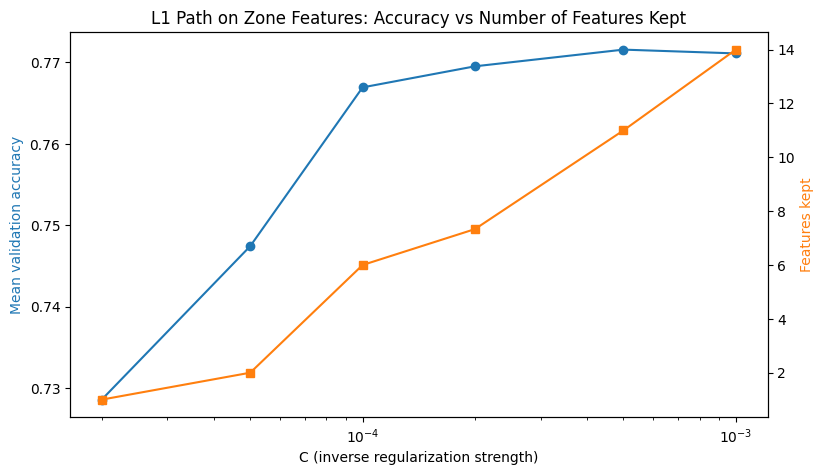

In [19]:
# Source: Raschka (2015), pp. 117 to 118 (L1 regularization path)
C_small = [0.00002, 0.00005, 0.0001, 0.0002, 0.0005, 0.001]
zone_path = []

for C in C_small:
    accs, n_kept = [], []
    for train_idx, val_idx in cv_object.split(X_zone_train_scaled, y_train):
        model = LogisticRegression(penalty='l1', C=C, solver='liblinear')
        model.fit(X_zone_train_scaled.iloc[train_idx], y_train.iloc[train_idx])
        accs.append(mt.accuracy_score(y_train.iloc[val_idx], model.predict(X_zone_train_scaled.iloc[val_idx])))
        n_kept.append((model.coef_[0] != 0).sum())
    zone_path.append({'C': C, 'mean_accuracy': np.mean(accs), 'features_kept': np.mean(n_kept)})

zone_path_df = pd.DataFrame(zone_path)
display(zone_path_df.round({'C': 6, 'mean_accuracy': 4, 'features_kept': 2}))

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(zone_path_df['C'], zone_path_df['mean_accuracy'], marker='o', color=cover_type_colors['Spruce/Fir'])
ax1.set_xscale('log')
ax1.set_xlabel('C (inverse regularization strength)')
ax1.set_ylabel('Mean validation accuracy', color=cover_type_colors['Spruce/Fir'])
ax2 = ax1.twinx()
ax2.plot(zone_path_df['C'], zone_path_df['features_kept'], marker='s', color=cover_type_colors['Lodgepole Pine'])
ax2.set_ylabel('Features kept', color=cover_type_colors['Lodgepole Pine'])
plt.title('L1 Path on Zone Features: Accuracy vs Number of Features Kept')
plt.show()

With a single feature left, the accuracy score is still 72.86%, about 16 percentage points over the baseline. It climbs rapidly up to 6 features (accuracy score of 76.69%) before it plateaus. Going from 6 to 14 features adds less than half a point. The best point on the path is 11 features at an accuracy score of 77.16%, and the full 14 feature zone model has an accuracy score of 77.11%, which is close to the accuracy score of 77.48% of the 50 feature model. The 7.33 features kept just means one borderline feature made it in some splits and not others.

Next, we printed which features survive at each C value. The order they come back in is an importance ranking.

In [20]:
# features that survive at each C, refit on the full training set
for C in C_small:
    model = LogisticRegression(penalty='l1', C=C, solver='liblinear')
    model.fit(X_zone_train_scaled, y_train)
    kept_now = pd.Series(model.coef_[0], index=zone_features)
    kept_now = kept_now[kept_now != 0].sort_values(key=abs, ascending=False)

    print(f"==== C = {C}: {len(kept_now)} features ====")
    for name, w in kept_now.items():
        direction = 'Spruce/Fir' if w > 0 else 'Lodgepole Pine'
        print(f"  {name:40s} {w:+.3f}  (toward {direction})")
    print()

==== C = 2e-05: 1 features ====
  Elevation                                +0.526  (toward Spruce/Fir)



==== C = 5e-05: 4 features ====
  Elevation                                +0.952  (toward Spruce/Fir)
  geologic_igneous and metamorphic         -0.150  (toward Lodgepole Pine)
  Horizontal_Distance_To_Hydrology         -0.058  (toward Lodgepole Pine)
  aspect_cos                               +0.051  (toward Spruce/Fir)



==== C = 0.0001: 6 features ====
  Elevation                                +1.197  (toward Spruce/Fir)
  geologic_igneous and metamorphic         -0.245  (toward Lodgepole Pine)
  Horizontal_Distance_To_Hydrology         -0.217  (toward Lodgepole Pine)
  aspect_cos                               +0.132  (toward Spruce/Fir)
  Hillshade_Noon                           -0.101  (toward Lodgepole Pine)
  climatic_alpine                          +0.094  (toward Spruce/Fir)



==== C = 0.0002: 9 features ====
  Elevation                                +1.373  (toward Spruce/Fir)
  Horizontal_Distance_To_Hydrology         -0.313  (toward Lodgepole Pine)
  geologic_igneous and metamorphic         -0.307  (toward Lodgepole Pine)
  aspect_cos                               +0.177  (toward Spruce/Fir)
  Hillshade_Noon                           -0.174  (toward Lodgepole Pine)
  climatic_alpine                          +0.169  (toward Spruce/Fir)
  Wilderness_Area2                         -0.044  (toward Lodgepole Pine)
  climatic_montane                         -0.008  (toward Lodgepole Pine)
  Horizontal_Distance_To_Roadways          -0.003  (toward Lodgepole Pine)



==== C = 0.0005: 11 features ====
  Elevation                                +1.529  (toward Spruce/Fir)
  Horizontal_Distance_To_Hydrology         -0.373  (toward Lodgepole Pine)
  geologic_igneous and metamorphic         -0.354  (toward Lodgepole Pine)
  climatic_alpine                          +0.231  (toward Spruce/Fir)
  Hillshade_Noon                           -0.225  (toward Lodgepole Pine)
  aspect_cos                               +0.198  (toward Spruce/Fir)
  Wilderness_Area2                         -0.140  (toward Lodgepole Pine)
  Horizontal_Distance_To_Roadways          -0.073  (toward Lodgepole Pine)
  climatic_montane                         -0.032  (toward Lodgepole Pine)
  Hillshade_9am                            -0.027  (toward Lodgepole Pine)
  Vertical_Distance_To_Hydrology           -0.018  (toward Lodgepole Pine)



==== C = 0.001: 14 features ====
  Elevation                                +1.591  (toward Spruce/Fir)
  Horizontal_Distance_To_Hydrology         -0.391  (toward Lodgepole Pine)
  geologic_igneous and metamorphic         -0.372  (toward Lodgepole Pine)
  climatic_alpine                          +0.256  (toward Spruce/Fir)
  Hillshade_Noon                           -0.251  (toward Lodgepole Pine)
  aspect_cos                               +0.198  (toward Spruce/Fir)
  Wilderness_Area2                         -0.176  (toward Lodgepole Pine)
  Horizontal_Distance_To_Roadways          -0.103  (toward Lodgepole Pine)
  Hillshade_9am                            -0.052  (toward Lodgepole Pine)
  climatic_montane                         -0.042  (toward Lodgepole Pine)
  Vertical_Distance_To_Hydrology           -0.036  (toward Lodgepole Pine)
  Horizontal_Distance_To_Fire_Points       +0.016  (toward Spruce/Fir)
  geologic_mixed sedimentary               -0.006  (toward Lodgepole Pine)
  climat

The order at which features survive at each C value follows: `Elevation`, `geologic_igneous and metamorphic`, `Horizontal_Distance_To_Hydrology`, `aspect_cos`, `Hillshade_Noon`, `climatic_alpine`, `Wilderness_Area2`, `climatic_montane`, and `Horizontal_Distance_To_Roadways`. No weight ever changes sign as the C value grows. They only get bigger as the penalty loosens, the same pattern as Raschka's regularization path. Therefore, the directions are stable, not an artifact of one setting.

### <a id="w_min"></a>7.4 The minimal model

The path flattens at 6 features, so we fit that model (C = 0.0001) and score it once on the test set.

Minimal model training time: 0.97 s
Minimal model test accuracy: 0.7728
Full model test accuracy:    0.7788
Confusion matrix:
 [[45181 11480]
 [11020 31348]]



6 of 25 features kept


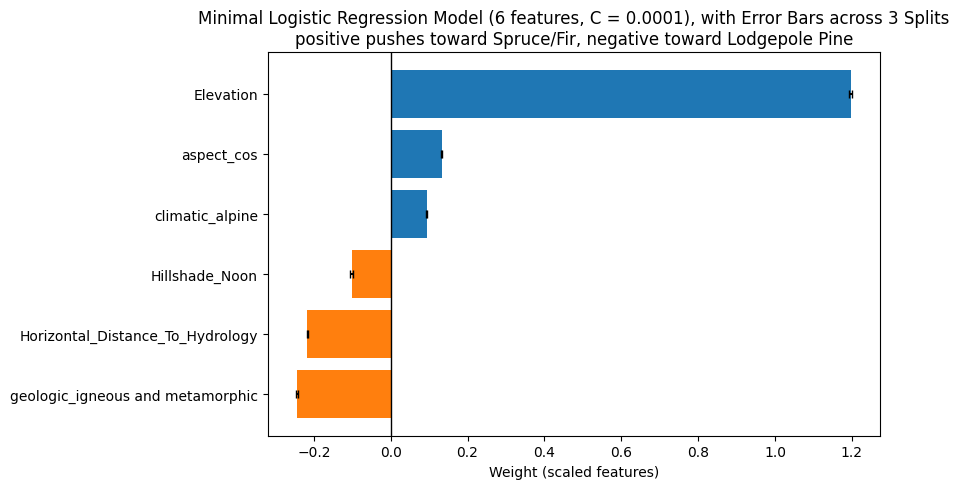

,weight,split_std,odds_multiplier
Elevation,1.197,0.004,3.311
geologic_igneous and metamorphic,-0.245,0.003,0.783
Horizontal_Distance_To_Hydrology,-0.217,0.002,0.805
aspect_cos,0.132,0.002,1.142
Hillshade_Noon,-0.101,0.003,0.904
climatic_alpine,0.094,0.001,1.099


In [21]:
# minimal model: L1 at C=0.0001 on the zone features, 6 features survive
C_min = 0.0001
min_clf = LogisticRegression(penalty='l1', C=C_min, solver='liblinear')

start = time.time()
min_clf.fit(X_zone_train_scaled, y_train)
min_time = time.time() - start

y_hat_min = min_clf.predict(X_zone_test_scaled)
print(f"Minimal model training time: {min_time:.2f} s")
print("Minimal model test accuracy: {:.4f}".format(mt.accuracy_score(y_test, y_hat_min)))
print("Full model test accuracy:    {:.4f}".format(mt.accuracy_score(y_test, y_hat_lr)))
print("Confusion matrix:\n", mt.confusion_matrix(y_test, y_hat_min))

# error bars across the 3 splits, same as section 7.1
min_split_weights = []
for train_idx, val_idx in cv_object.split(X_zone_train_scaled, y_train):
    split_model = LogisticRegression(penalty='l1', C=C_min, solver='liblinear')
    split_model.fit(X_zone_train_scaled.iloc[train_idx], y_train.iloc[train_idx])
    min_split_weights.append(split_model.coef_[0])
min_split_weights = np.array(min_split_weights)

min_weights = pd.DataFrame({'weight': min_clf.coef_[0],
                            'split_std': min_split_weights.std(axis=0)},
                           index=zone_features)
min_kept = min_weights[min_weights['weight'] != 0].sort_values('weight')
print(f"\n{len(min_kept)} of {len(zone_features)} features kept")

plt.figure(figsize=(9, 5))
colors = [cover_type_colors['Spruce/Fir'] if w > 0 else cover_type_colors['Lodgepole Pine']
          for w in min_kept['weight']]
plt.barh(min_kept.index, min_kept['weight'], xerr=min_kept['split_std'], color=colors, capsize=3)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel('Weight (scaled features)')
plt.title(f'Minimal Logistic Regression Model ({len(min_kept)} features, C = {C_min}), '
          'with Error Bars across 3 Splits\npositive pushes toward Spruce/Fir, negative toward Lodgepole Pine')
plt.tight_layout()
plt.show()

# odds multiplier per one standard deviation increase
min_table = min_kept.reindex(min_kept['weight'].abs().sort_values(ascending=False).index).copy()
min_table['odds_multiplier'] = np.exp(min_table['weight'])
min_table.round(3)

Using six features, we have an accuracy score of 77.28% on the test set. That is only 0.6 points under the full model, and it trains about 3.7 times faster (0.97 vs 3.59 seconds of runtime). It is also a bit more balanced: Spruce/Fir recall goes from 0.72 to 0.74, and the errors split almost evenly (11,480 vs 11,020). The error bars are small and none of them crosses zero, so all six directions hold across splits.

The odds multiplier column is the plain version of each weight: how the odds of Spruce/Fir change for one standard deviation more of that feature. One standard deviation of higher elevation roughly triples the odds (×3.31). Every other feature moves the odds by only 10 to 22 percent. To get elevation in meters, we convert its weight below.

In [22]:
# Elevation weight per 100 m instead of per standard deviation
elev_sd = zone_scl.scale_[zone_features.index('Elevation')]
w_elev = min_weights.loc['Elevation', 'weight']
print(f"Elevation standard deviation (training set): {elev_sd:.1f} m")
print(f"Odds multiplier per 100 m higher: {np.exp(w_elev / elev_sd * 100):.2f}")

Elevation standard deviation (training set): 202.6 m
Odds multiplier per 100 m higher: 1.81


### <a id="w_meaning"></a>7.5 What the weights tell us

Elevation does most of the work as it is the only feature that survives the strongest penalty, and alone, it has an accuracy score of 72.86%. One standard deviation of `Elevation` is 202.6 m, so every 100 m higher multiplies the odds of Spruce/Fir by about 1.81 in the minimal model and by about 2.19 with the weaker penalty at C = 0.001. That 202.6 m is almost exactly the gap that we found in Lab One between the two species' average elevations (about 3,133 m for Spruce/Fir and 2,939 m for Lodgepole Pine). Moving from a typical Lodgepole Pine site to a typical Spruce/Fir site roughly triples the odds on its own. It is the subalpine zoning from Lab One, where Spruce/Fir takes over higher up, where it is colder.

The next group is about moisture and sun. North facing slopes push toward Spruce/Fir (`aspect_cos` is 1 for north and −1 for south, ×1.14). More midday sun (`Hillshade_Noon`, ×0.90) and more distance from water (`Horizontal_Distance_To_Hydrology`, ×0.81) push toward Lodgepole Pine. Seeing that, Spruce/Fir likes cooler, shadier, wetter spots, whereas, Lodgepole Pine likes sunnier, drier spots. That matches our Lab One polar histogram, where north and northeast slopes held the moisture and the forest. At the same elevation, these are what decide how cold and wet a site actually is.

Soil geology adds a smaller push. Igneous and metamorphic soils lean towards Lodgepole Pine (×0.78), whereas alpine soils lean towards Spruce/Fir (×1.10). The 50 feature model says the same with individual soil types. Lodgepole Pine is known to handle coarse, well drained soils, which fits, but we see that as a plausible reading, not something this data proves.

Two weights looked backwards to us at first. Neota (`Wilderness_Area2`) is 62% Spruce/Fir in Lab One, yet its weight is negative. Spruce/Fir sits farther from roads overall, yet `Horizontal_Distance_To_Roadways` is negative too. The weights are conditional on everything else, and both variables are tied to elevation. Neota is mostly Spruce/Fir because it is high, and roadway distance tracks elevation (+0.37 in Lab One's correlation matrix). Once elevation is in the model, what is left of their effect points slightly the other way. They do not contradict Lab One. They show what each variable adds beyond elevation.

On magnitudes, at C = 0.0001, the L1 penalty shrinks every weight, so the minimal model's multipliers understate the real effects. `Elevation` is 1.20 there but 1.59 at C = 0.001. We rely on the ranking and the directions, and those held at every C value we tried and in both the 50 and 25 feature models.

In Lab One, we mentioned that a trustworthy model should lean on elevation and on terrain variables that make ecological sense, not on a weak or meaningless attribute. These weights do exactly that.

## <a id="sv"></a>8. Looking at the Support Vectors

### <a id="sv_count"></a>8.1 How many support vectors, and from which class

First, we determine how many rows the final SVM kept as support vectors and from which class.

In [23]:
# Source: course notebook, cell 29
print("support_vectors_ shape:", svm_clf.support_vectors_.shape)
print("support_ shape:", svm_clf.support_.shape)
print("n_support_ (Lodgepole Pine, Spruce/Fir):", svm_clf.n_support_)
print("Share of training rows used as support vectors: {:.1%}".format(len(svm_clf.support_) / len(X_svm_train)))
print("Share per class (Lodgepole Pine, Spruce/Fir):",
      (svm_clf.n_support_ / y_svm_train.value_counts().sort_index().values).round(3))

support_vectors_ shape: (12252, 50)
support_ shape: (12252,)
n_support_ (Lodgepole Pine, Spruce/Fir): [6530 5722]
Share of training rows used as support vectors: 61.3%
Share per class (Lodgepole Pine, Spruce/Fir): [0.571 0.669]


We find that 12,252 of the 20,000 rows (about 61%) became support vectors: 6,530 Lodgepole Pine and 5,722 Spruce/Fir. Relative to the class size, Spruce/Fir rows got picked more often (about 67% vs 57%), so more of that class sits near the boundary. That lines up with Spruce/Fir having the lower recall in every model. The SVM was trained on the main 50 feature set, so each support vector has 50 values. The zones in section 7 were only for interpreting the logistic regression weights.

### <a id="sv_compare"></a>8.2 Support vectors vs all training rows

Like the course notebook, we pull out the support vector rows and compare them with all rows in the subsample, by class. We use unscaled values so the axes are in real units, and the features that the minimal logistic regression kept.

Support vectors: 12252 of 20000 training rows
cover_type
Lodgepole Pine    6530
Spruce/Fir        5722
Name: count, dtype: int64


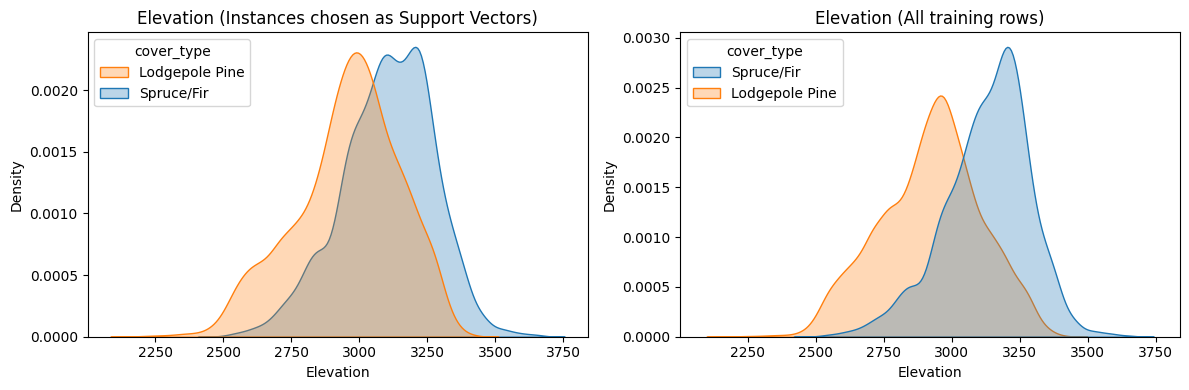

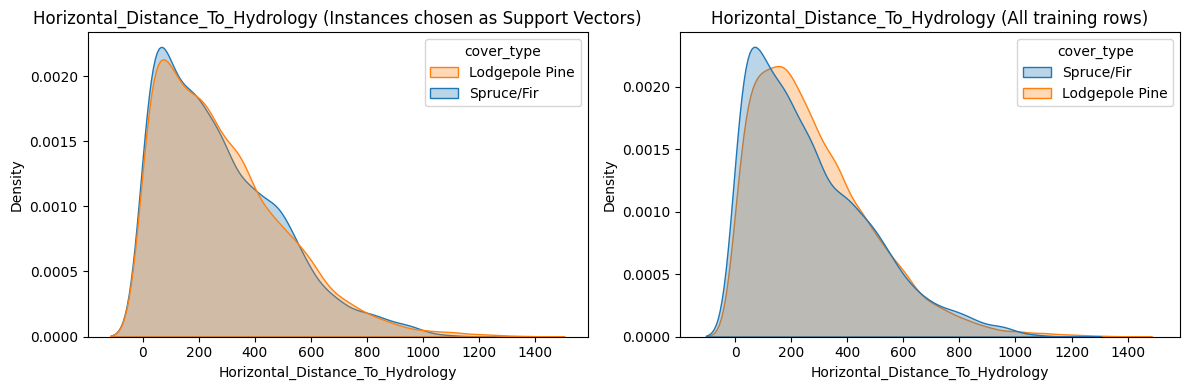

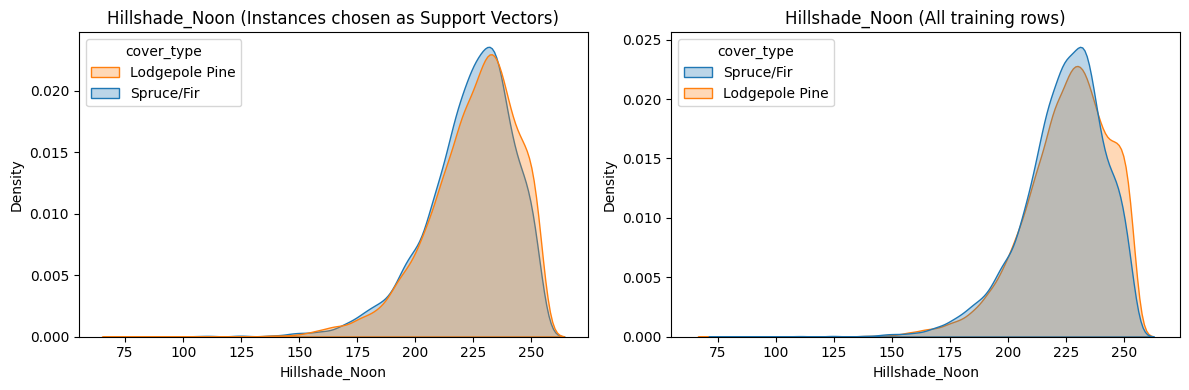

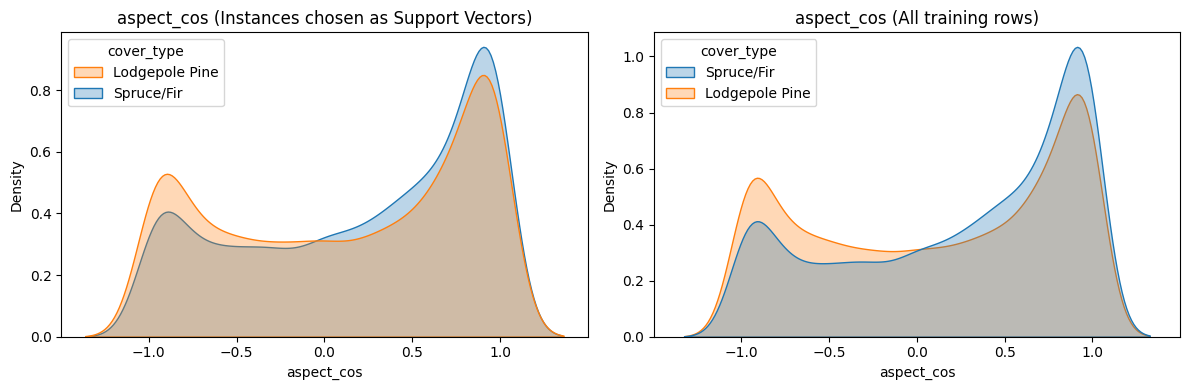

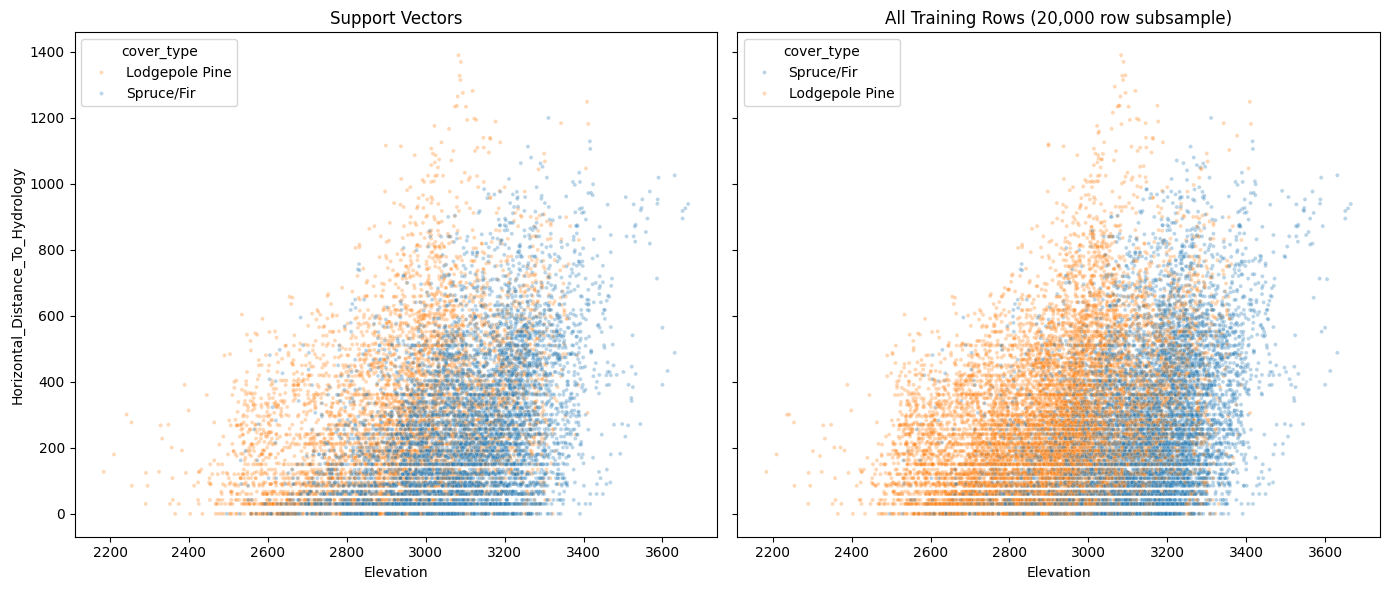

In [24]:
# Source: course notebook, cells 31 and 32. Changed: unscaled units, features from the minimal model
df_svm_train = X_train.loc[X_svm_train.index].copy()
df_svm_train['cover_type'] = np.where(y_svm_train.values == 1, 'Spruce/Fir', 'Lodgepole Pine')

df_support = df_svm_train.iloc[svm_clf.support_].copy()
print(f"Support vectors: {len(df_support)} of {len(df_svm_train)} training rows")
print(df_support['cover_type'].value_counts())

vars_to_plot = ['Elevation', 'Horizontal_Distance_To_Hydrology', 'Hillshade_Noon', 'aspect_cos']

for v in vars_to_plot:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
    sns.kdeplot(data=df_support, x=v, hue='cover_type', palette=cover_type_colors,
                common_norm=False, fill=True, alpha=0.3, ax=axes[0])
    axes[0].set_title(v + ' (Instances chosen as Support Vectors)')
    sns.kdeplot(data=df_svm_train, x=v, hue='cover_type', palette=cover_type_colors,
                common_norm=False, fill=True, alpha=0.3, ax=axes[1])
    axes[1].set_title(v + ' (All training rows)')
    plt.tight_layout()
    plt.show()

# joint plot, from the course notebook's hint in cell 33
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
sns.scatterplot(data=df_support, x='Elevation', y='Horizontal_Distance_To_Hydrology', hue='cover_type',
                palette=cover_type_colors, alpha=0.3, s=8, ax=axes[0])
axes[0].set_title('Support Vectors')
sns.scatterplot(data=df_svm_train, x='Elevation', y='Horizontal_Distance_To_Hydrology', hue='cover_type',
                palette=cover_type_colors, alpha=0.3, s=8, ax=axes[1])
axes[1].set_title('All Training Rows (20,000 row subsample)')
plt.tight_layout()
plt.show()

The two classes overlap more among the support vectors than in the full data, which is what we expect from rows sitting near the boundary.

`Elevation` shows it best. Across all rows, the two classes peak about 250 m apart, near 2,950 m for Lodgepole Pine and 3,200 m for Spruce/Fir. Among the support vectors, the peaks slide toward each other, and both classes pile up between about 2,900 and 3,250 m. The easy cases at the ends mostly drop out: Lodgepole Pine below 2,700 m and Spruce/Fir above 3,350 m. That band is almost exactly the 2,900 to 3,200 m range where Lab One found the two species sharing ground. The SVM found the same hard region by itself.

The other features lose most of their difference. Across all rows, Spruce/Fir peaks closer to water (around 70 m vs about 150 m), and Lodgepole Pine has a shoulder at very high midday sun (245 to 255). Among the support vectors, both differences nearly vanish. These features help with the easy rows but cannot split the hard ones. `aspect_cos` keeps a smaller gap: even in the hard region, Spruce/Fir still leans north facing and Lodgepole Pine south facing.

The joint plot says the same. Across all rows, there is a Lodgepole Pine block on the lower left and a Spruce/Fir block on the right. The support vectors fill the mixed band from about 2,900 to 3,300 m, and the low elevation Lodgepole Pine corner thins out. The horizontal stripes in distance to water come from the 30 m grid the data was measured on.

So most of what makes this problem hard is one narrow elevation band where the two species overlap and the moisture and sun signals go quiet. Outside that band, elevation mostly settles it. One caveat though: with 61% of rows as support vectors, the support vector set still looks a lot like the full data, so the contrast is moderate. That comes from the fairly large gamma (0.5), which bends the boundary tightly and puts many rows on or near the margin.

## <a id="summary"></a>9. Summary of Key Findings

- The RBF SVM is the most accurate at 86.63%, training on only 20,000 rows. Logistic regression (accuracy score of 77.88%), the linear SVM (accuracy score of 77.98%) and LDA (accuracy score of 77.77%) all are tied. The increase in accuracy score comes from the curved boundary, not from the SVM itself.
- Every model beat the baseline accuracy score of 57.22%, which is what always guessing Lodgepole Pine would get. Spruce/Fir was the harder class to predict in every model.
- The linear models were far cheaper: under 4 seconds to train on all 396,112 rows and near instant prediction. The RBF SVM needed about 73 seconds just to predict the test set.
- Tuning the C value barely changed our logistic regression. For the SVM, gamma was the key parameter as it increases the test accuracy from 80.37% to 86.63%.
- `Elevation` dominates among all the features. Alone, it reaches an accuracy score of 72.86%, and every 100 m higher multiplies the odds of Spruce/Fir by about 1.8 to 2.2. Moisture and sun (distance to water, slope direction, midday sun) plus soil geology refine the accuracy score.
- Six features get within 0.6 points of the full 50 feature model.
- The support vectors sit in the same 2,900 to 3,200 m band that Lab One flagged, where the moisture and sun differences between the two species mostly disappear.
- The models lean on variables that make ecological sense, which was what our Lab One tested for trusting what a model learned.